# Freedom to Make Life Choices

> How much freedom contributes to one's feeling of happiness

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['FTMLC']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Summary 

In [4]:
train_df[COLUMN].info()

FreedomToMakeLifeChoices_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
FreedomToMakeLifeChoices_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

FreedomToMakeLifeChoices_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Freedom to make life choices
Non-Null Count  Dtype  
--------------  -----  
1537 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Freedom to make life choices,1537.0,0.741882,0.142326,0.26,0.646,0.763,0.855,0.985,8


In [5]:
missing_values_FreedomToMakeLifeChoices = train_df[COLUMN].isna().sum()
count_FreedomToMakeLifeChoices = train_df[COLUMN].count()

print(f"{missing_values_FreedomToMakeLifeChoices} missing values out of {count_FreedomToMakeLifeChoices} -> {round(missing_values_FreedomToMakeLifeChoices / count_FreedomToMakeLifeChoices, 2)}%")

22 missing values out of 1537 -> 0.01%


# Plots

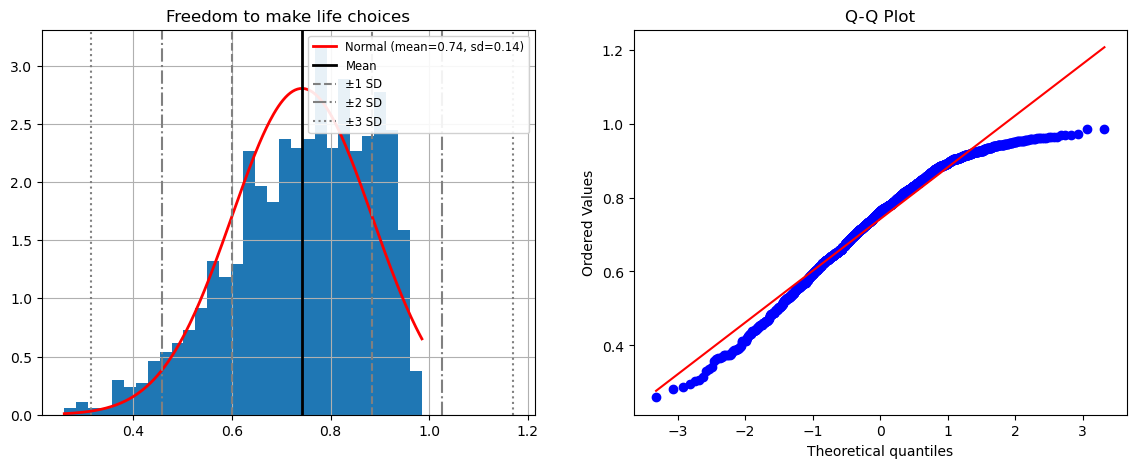

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Freedom to make life choices'}, xlabel='Freedom to make life choices', ylabel='Life Ladder'>

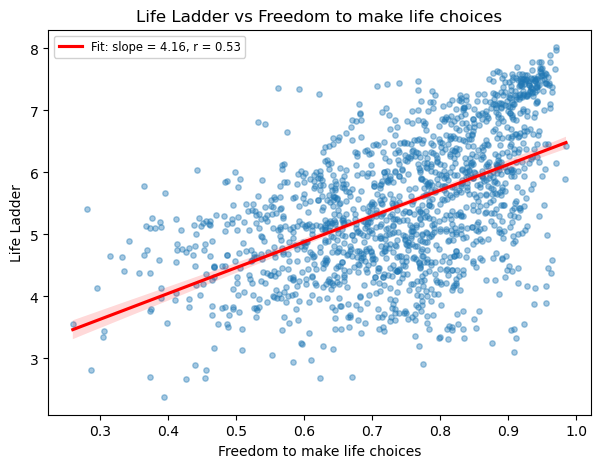

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Freedom to make life choices",
	target=TARGET,
)

In [8]:
correlation_to_target_FreedomToMakeLifeChoices = train_df[TARGET].corr(train_df["Freedom to make life choices"])
print(f"Correlation: {correlation_to_target_FreedomToMakeLifeChoices:.3f}")

Correlation: 0.530


# Skew & Kurtosis

In [9]:
FreedomToMakeLifeChoicesSkew = train_df[COLUMN].skew()
FreedomToMakeLifeChoicesSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Freedom to make life choices"])
FreedomToMakeLifeChoicesKurtosis = train_df[COLUMN].kurt()
FreedomToMakeLifeChoicesKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Freedom to Make Life Choices Skew: {FreedomToMakeLifeChoicesSkew:.3f} -> {FreedomToMakeLifeChoicesSkew_RuleOfThumb}')
print(f'Freedom to Make Life Choices Kurtosis: {FreedomToMakeLifeChoicesKurtosis:.3f} -> {FreedomToMakeLifeChoicesKurtosis_RuleOfThumb}')

Freedom to Make Life Choices Skew: -0.606 -> Moderately skewed
Freedom to Make Life Choices Kurtosis: -0.158 -> Mesokurtic (near-normal tails)


In [10]:
FreedomToMakeLifeChoicesSkewTransformed = compare_all_transforms(series=train_df["Freedom to make life choices"])
FreedomToMakeLifeChoicesSkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
rank,-0.606357,-0.001960,0.604397,-0.157783,-1.199944,-1.042161,Roughly symmetric
yeo_johnson,-0.606357,-0.100027,0.506331,-0.157783,-0.847414,-0.689631,Roughly symmetric
cube,-0.606357,0.129260,0.735618,-0.157783,-0.962928,-0.805145,Roughly symmetric
square,-0.606357,-0.189701,0.416656,-0.157783,-0.806723,-0.648940,Roughly symmetric
log1p,-0.606357,-0.805919,-0.199562,-0.157783,0.313809,0.471592,Moderately skewed
sqrt,-0.606357,-0.873144,-0.266786,-0.157783,0.534852,0.692635,Moderately skewed
log,-0.606357,-1.198154,-0.591797,-0.157783,1.680083,1.837865,Highly skewed


---

### Notes / Observations
#### General
- 22 missing values (1.4% of rows).
- A 0 to 1 share ranging from 0.26 to 0.99 (mean 0.74, median 0.76).
- Moderately left skewed (skew -0.61, kurtosis -0.16): most countries sit between 0.6 and 0.95, with 8 low IQR outliers (below about 0.33).
- Moderate positive link to happiness (r = 0.53). The scatter is wide in the middle, but very high freedom (above 0.9) lines up with the happiest countries.
- Tied to Positive affect (r = 0.61) and, inversely, to Corruption (r = -0.48), but only loosely to GDP (r = 0.36).
- **Takeaway:** useful mid strength predictor that adds information beyond wealth.

#### Transforming
- Mild skew, so a transform is optional; the tails already look normal.
- yeo_johnson (skew -0.10), cube (0.13) and square (-0.19) all make it roughly symmetric.
- log and sqrt make it worse (-1.20, -0.87) because they stretch the low tail.
- **Pick:** square for simplicity, or yeo_johnson to stay consistent with the other left skewed features.

#### Scaling
- Already in a 0 to 1 range, but StandardScaler keeps it consistent with the other features.
- Few outliers, so the mean and std are not distorted.

#### Imputing
- Only moderate links to other features (Positive affect r = 0.61, Corruption r = -0.48), so model based imputation gains little.
- Median SimpleImputer (0.763) is a reasonable choice; it sits slightly above the mean (0.742) because of the left skew.